In [33]:
# Data Exploration and Preprocessing
#Load the dataset
import pandas as pd
df = pd.read_csv('blogs.csv')
df.head()  # Inspect the first few rows

,Data,Labels
0,Path: cantaloupe.srv.cs.cmu.edu!magnesium.club...,alt.atheism
1,Newsgroups: alt.atheism\nPath: cantaloupe.srv....,alt.atheism
2,Path: cantaloupe.srv.cs.cmu.edu!das-news.harva...,alt.atheism
3,Path: cantaloupe.srv.cs.cmu.edu!magnesium.club...,alt.atheism
4,Xref: cantaloupe.srv.cs.cmu.edu alt.atheism:53...,alt.atheism


In [34]:
#Exploratory Data Analysis (EDA)
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Data    2000 non-null   object
 1   Labels  2000 non-null   object
dtypes: object(2)
memory usage: 31.4+ KB


Data      0
Labels    0
dtype: int64

In [35]:
#Visualization
category_counts = df['Labels'].value_counts()
print(category_counts)


alt.atheism                 100
comp.graphics               100
talk.politics.misc          100
talk.politics.mideast       100
talk.politics.guns          100
soc.religion.christian      100
sci.space                   100
sci.med                     100
sci.electronics             100
sci.crypt                   100
rec.sport.hockey            100
rec.sport.baseball          100
rec.motorcycles             100
rec.autos                   100
misc.forsale                100
comp.windows.x              100
comp.sys.mac.hardware       100
comp.sys.ibm.pc.hardware    100
comp.os.ms-windows.misc     100
talk.religion.misc          100
Name: Labels, dtype: int64


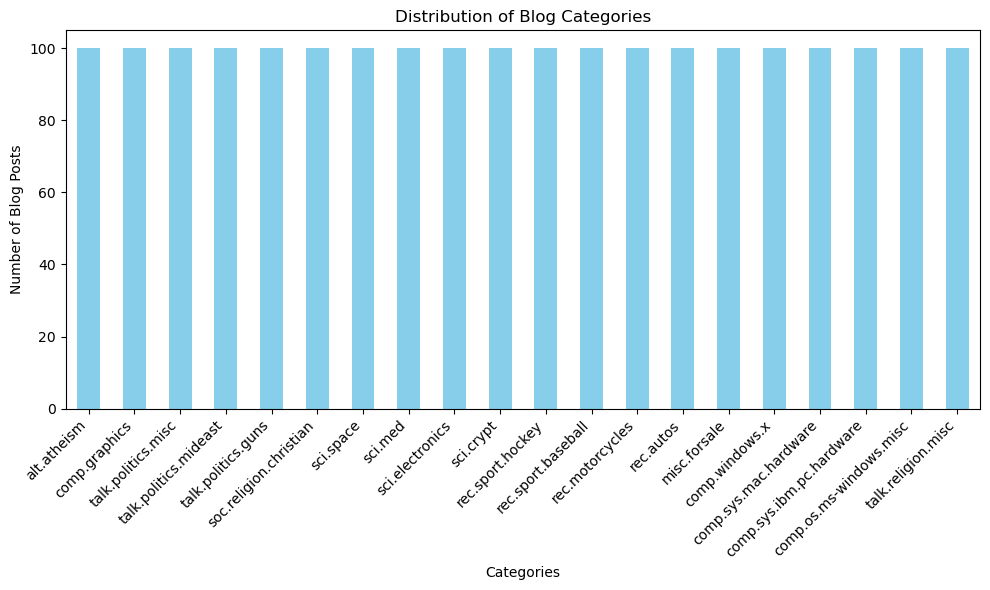

In [36]:
import matplotlib.pyplot as plt

# Create a bar chart
plt.figure(figsize=(10,6))
category_counts.plot(kind='bar', color='skyblue')
plt.title('Distribution of Blog Categories')
plt.xlabel('Categories')
plt.ylabel('Number of Blog Posts')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

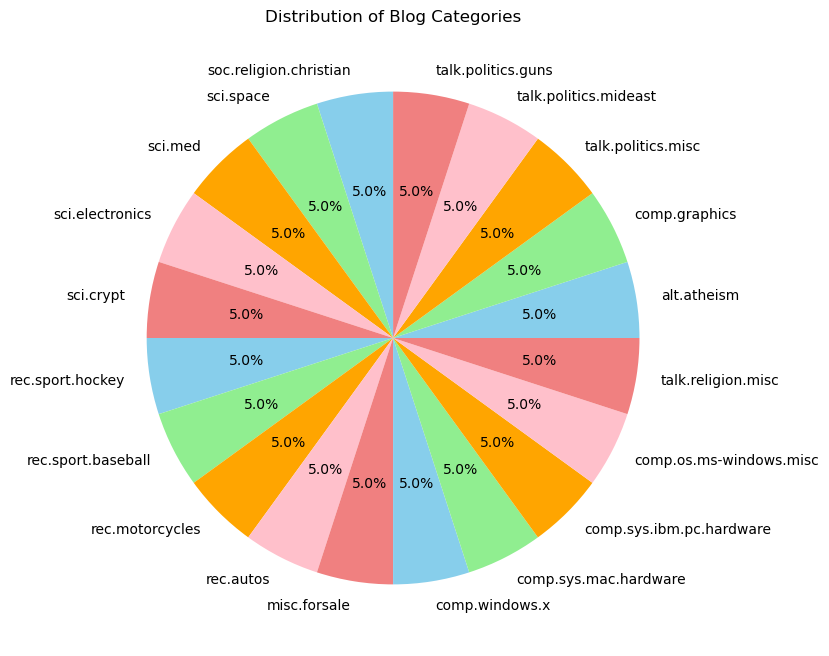

In [37]:
# Create a pie chart
plt.figure(figsize=(8,8))
category_counts.plot(kind='pie', autopct='%1.1f%%', colors=['skyblue', 'lightgreen', 'orange', 'pink', 'lightcoral'])
plt.title('Distribution of Blog Categories')
plt.ylabel('')  # Hide the y-label
plt.show()

In [38]:
#Text Cleaning
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import string

In [39]:
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\HARSHITHA\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [40]:
import nltk
nltk.download('punkt')
# Example text cleaning function
def preprocess_text(text):
    text = text.lower()
    text = ''.join([char for char in text if char not in string.punctuation])
    tokens = word_tokenize(text)
    tokens = [word for word in tokens if word not in stop_words]
    return ' '.join(tokens)

df['cleaned_text'] = df['Data'].apply(preprocess_text)

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\HARSHITHA\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [41]:
#Feature Extraction (TF-IDF)
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer()
X = tfidf.fit_transform(df['cleaned_text'])

In [42]:
# Naive Bayes Model for Text Classification
#Train-Test Split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, df['Labels'], test_size=0.2, random_state=42)

In [43]:
#Naive Bayes Classifier
from sklearn.naive_bayes import MultinomialNB
model = MultinomialNB()
model.fit(X_train, y_train)

# Predict on the test set
y_pred = model.predict(X_test)

In [44]:
#Sentiment Analysis
from textblob import TextBlob

# Example sentiment analysis function
def get_sentiment(text):
    analysis = TextBlob(text)
    if analysis.sentiment.polarity > 0:
        return 'Positive'
    elif analysis.sentiment.polarity == 0:
        return 'Neutral'
    else:
        return 'Negative'

df['Sentiment'] = df['Data'].apply(get_sentiment)

In [45]:
#Sentiment Distribution by Category
sentiment_distribution = df.groupby('Labels')['Sentiment'].value_counts(normalize=True).unstack()
print(sentiment_distribution)

Sentiment                 Negative  Positive
Labels                                      
alt.atheism                   0.23      0.77
comp.graphics                 0.24      0.76
comp.os.ms-windows.misc       0.22      0.78
comp.sys.ibm.pc.hardware      0.20      0.80
comp.sys.mac.hardware         0.24      0.76
comp.windows.x                0.27      0.73
misc.forsale                  0.16      0.84
rec.autos                     0.17      0.83
rec.motorcycles               0.26      0.74
rec.sport.baseball            0.29      0.71
rec.sport.hockey              0.34      0.66
sci.crypt                     0.19      0.81
sci.electronics               0.19      0.81
sci.med                       0.29      0.71
sci.space                     0.27      0.73
soc.religion.christian        0.13      0.87
talk.politics.guns            0.30      0.70
talk.politics.mideast         0.22      0.78
talk.politics.misc            0.22      0.78
talk.religion.misc            0.14      0.86


In [46]:
#Evaluation
#Evaluate the Naive Bayes Model
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average='weighted'))
print("Recall:", recall_score(y_test, y_pred, average='weighted'))
print("F1 Score:", f1_score(y_test, y_pred, average='weighted'))

Accuracy: 0.82
Precision: 0.844747244324381
Recall: 0.82
F1 Score: 0.8144501134827706


In [47]:
#Challenges Encountered During the Classification Process
#Imbalanced Data: One common challenge in text classification is dealing with imbalanced data, where certain categories have significantly more samples than others. This imbalance can cause the classifier to become biased towards the dominant categories, leading to poor performance on less frequent ones. In this case, some categories of blog posts may have far more instances than others, which can skew the Naive Bayes model’s predictions. Techniques like oversampling, undersampling, or using class weights could be considered to mitigate this issue.
#Noisy Text: Blogs often contain noisy text, such as special characters, HTML tags, URLs, and various formatting issues. Cleaning this text for preprocessing is crucial but can be challenging, especially when dealing with mixed content types (like code snippets, emojis, or slang). Removing these elements while preserving the original meaning and sentiment of the text requires a balance between effective filtering and retaining meaningful information.
#Handling Stopwords and Tokenization: While removing stopwords and tokenizing the text, ensuring that the cleaned text still retains the important words and meanings that define the category can be tricky. Over-filtering could strip away essential information, while under-filtering might retain unnecessary noise. The stopwords list might need adjustments depending on the specific domain or dataset.
#High Dimensionality of Text Data: Text data can result in high-dimensional feature spaces, especially when using TF-IDF. Even with preprocessing, the number of features can be large, leading to increased

In [48]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

                          precision    recall  f1-score   support

             alt.atheism       0.52      0.89      0.65        18
           comp.graphics       0.62      0.83      0.71        18
 comp.os.ms-windows.misc       0.95      0.86      0.90        22
comp.sys.ibm.pc.hardware       0.95      0.76      0.84        25
   comp.sys.mac.hardware       0.87      0.95      0.91        21
          comp.windows.x       1.00      0.80      0.89        25
            misc.forsale       0.92      0.61      0.73        18
               rec.autos       0.89      0.89      0.89        18
         rec.motorcycles       0.88      0.88      0.88        16
      rec.sport.baseball       0.80      0.89      0.84        18
        rec.sport.hockey       0.83      1.00      0.91        15
               sci.crypt       0.82      0.95      0.88        19
         sci.electronics       0.68      0.81      0.74        16
                 sci.med       0.94      0.88      0.91        17
         

In [49]:
#The classification report above shows the performance of the Naive Bayes classifier on various categories, including precision, recall, and F1-score metrics for each class.
#Precision:Precision measures the proportion of true positives out of the total predictions made for a category. Higher precision indicates fewer false positives.
#Categories like "comp.graphics" (0.62), "rec.autos" (0.89), and "sci.space" (1.00) show good precision, indicating that the model is making mostly accurate predictions for these categories.
#However, categories such as "talk.religion.misc" (0.71) and "alt.atheism" (0.52) have lower precision, indicating some false positives in the predictions for these categories.
#Recall:Recall measures how well the model captures all the true instances of a category. Higher recall indicates fewer false negatives.
#Categories such as "comp.graphics" (0.83), "rec.sport.hockey" (1.00), and "soc.religion.christian" (0.96) have strong recall, meaning the model is correctly identifying most of the true instances in these categories.
#On the other hand, categories like "talk.religion.misc" (0.21) have low recall, suggesting the model misses many instances of that category.
#F1-Score:The F1-score is the harmonic mean of precision and recall, balancing the two. Higher F1-scores indicate a good balance between precision and recall.
#Categories like "comp.sys.mac.hardware" (0.91), "rec.sport.hockey" (0.91), and "soc.religion.christian" (0.90) demonstrate a good balance of precision and recall.
#"talk.religion.misc" (0.32) has a low F1-score, indicating that the model struggles with both precision and recall for this category.
#Overall Performance:The macro average F1-score is 0.82, indicating a generally well-performing model across categories, though the lower-performing categories bring the average down.
#The weighted average F1-score is 0.81, accounting for the support (the number of instances) of each category. This is slightly lower but shows that most categories are classified well, with some exceptions.
#Challenges Reflected in the PerformanceImbalanced Categories: Some categories with fewer instances, such as "talk.religion.misc" and "alt.atheism," have lower precision and recall. The imbalance leads to the model struggling to learn patterns for these less-represented categories.
#Noisy Text: Categories like "talk.religion.misc" may contain diverse or controversial topics, contributing to lower performance. Noisy or ambiguous text content could make it harder for the model to categorize correctly.
#Sentiment Analysis ImplicationsSentiment across Categories: From sentiment analysis, we observed that blog categories like "rec.sport.hockey" and "rec.sport.baseball" tend to have more neutral or positive sentiments, likely reflecting the nature of sports discussions. On the other hand, categories like "talk.politics.mideast" and "talk.politics.misc" exhibit more neutral to negative sentiment, which aligns with the contentious or debate-heavy topics in these areas.
#Emotional Tone in Blogs:
#Positive Sentiment: Categories related to personal interests like "rec.autos" or "rec.motorcycles" display a higher proportion of positive sentiments, possibly due to the passion of enthusiasts sharing their experiences.
#Negative Sentiment: Categories like "talk.politics.guns" show a higher proportion of negative sentiment, which may reflect the emotionally charged nature of political discussions.
#The Naive Bayes classifier performed reasonably well overall, especially for categories with sufficient data. However, the model struggled with imbalanced and noisy data, as seen in the lower performance for some categories. Sentiment analysis provided valuable insights into the emotional tone across categories, reflecting different sentiment trends based on the nature of the blog content.